---
downloads:
  - file: tp04_chute_libre_frottements_teacher.ipynb
    title: Notebook enseignant
    filename: tp04_chute_libre_frottements_enseignant.ipynb
  - file: ../notebooks_student/tp04_chute_libre_frottements_student.ipynb
    title: Notebook étudiant
    filename: tp04_chute_libre_frottements_etudiant.ipynb
---

# TP 04 — Chute libre sans frottement

Dans ce TP, nous étudions la chute d'un point matériel dans un champ de
pesanteur uniforme, sans frottement de l'air.

:::{important} Version enseignant
Cette page présente la version **corrigée**, destinée aux enseignants.

Pour télécharger la version à distribuer aux étudiants et à déposer sur
Boostcamp, utilisez le bouton **Notebook étudiant** dans le menu de
téléchargement situé en haut de la page.

Les liens suivants ouvrent les notebooks dans Google Colab :

- [Notebook enseignant](https://colab.research.google.com/github/ECE-Ecole-Ingenieurs/cours-physique/blob/main/notebooks/tp04_chute_libre_frottements_teacher.ipynb) ;
- [Notebook étudiant](https://colab.research.google.com/github/ECE-Ecole-Ingenieurs/cours-physique/blob/main/notebooks_student/tp04_chute_libre_frottements_student.ipynb).
:::

**Exécutez la cellule suivante pour importer les bibliothèques nécessaires à ce TP.**

In [1]:
import numpy as np  # Manipulation des vecteurs et opérations matricielles
import matplotlib.pyplot as plt  # Tracé des figures 2D et 3D
from ipywidgets import interact, FloatSlider  # Widgets interactifs (curseurs)

## 1. Rappel de cours

En dynamique du point matériel, le principe fondamental de la dynamique
(PFD) relie les forces appliquées à un point matériel à son accélération
dans un référentiel galiléen :

$$
\overrightarrow{F} = m\overrightarrow{a}(M)_{/R}
$$

où $\overrightarrow{F}$ est la résultante des forces extérieures
appliquées au système.

Pour résoudre un problème de dynamique, on suit toujours la même méthode :
identifier le système et le référentiel, faire le bilan des forces,
choisir un repère adapté, projeter le PFD sur les axes de ce repère, puis
intégrer successivement l'accélération pour obtenir la vitesse puis la
position.

Dans ce TP, nous étudions la chute d'un point matériel $M$ de masse $m$,
lâché sans vitesse initiale d'une hauteur $h_0$, le long d'un axe $(Oz)$
vertical ascendant.

## 2. Chute libre sans frottement

Dans un référentiel galiléen, on s'intéresse à la chute libre d'un corps
$M$ de masse $m$, lâché sans vitesse initiale d'une hauteur $h_0$. On
néglige, dans un premier temps, les frottements dus à l'air.

### 2.1 Théorie

:::{admonition} ✍️ Questions
:class: tip

1. Déterminer, rigoureusement, l'équation horaire de la trajectoire du
   point $M$ notée $z(t)$.
:::

:::{admonition} 💡 Aide
:class: hint

Faites le bilan des forces s'exerçant sur $M$, appliquez le PFD, puis
projetez-le sur l'axe $(Oz)$. Intégrez ensuite l'accélération pour
obtenir $v(t)$, puis $v(t)$ pour obtenir $z(t)$, en utilisant les
conditions initiales $v(0)=0$ et $z(0)=h_0$.
:::

*Écrivez vos réponses ici (Markdown, $\LaTeX$…) :*

1. --

:::{admonition} Réponses
:class: note

Le point $M$ n'est soumis qu'à son poids
$\overrightarrow{P}=m\overrightarrow{g}$. Le PFD projeté sur $(Oz)$
donne $a_z=-g$.

En intégrant avec $v(0)=0$ : $v(t)=-gt$.

En intégrant à nouveau avec $z(0)=h_0$ :

$$
z(t) = -\frac{1}{2}gt^2 + h_0
$$
:::

:::{admonition} Appelez le professeur
:class: warning

Avant de passer à l'implémentation, faites valider votre raisonnement par
l'enseignant.
:::

### 2.2 Implémentation numérique

:::{admonition} 💻 Code
:class: tip

Complétez la fonction `chute_libre` qui renvoie l'altitude $z(t)$ du
point $M$ à partir du temps $t$ et de la hauteur initiale $h_0$. On
prendra $g=9.81\ \mathrm{m/s^2}$.
:::

In [2]:
def chute_libre(t, h0):
    """
    Calcule l'altitude z(t) lors d'une chute libre sans frottement.

    Paramètres
    ----------
    t : float ou np.ndarray
        Instant(s) considéré(s) [s].
    h0 : float
        Hauteur initiale [m].

    Renvoie
    -------
    z : float ou np.ndarray
        Altitude du point M [m].
    """
    g = 9.81
    z = -0.5 * g * t**2 + h0

    return z

:::{admonition} 💻 Code
:class: tip

Nous allons commencer à créer des graphes ! Complétez la fonction
`tracer_trajectoire_z`, qui trace l'altitude `z(t)` en fonction du
temps.

Le code crée déjà une figure avec deux axes
(`fig, (ax1, ax2) = plt.subplots(...)`). Vous devez compléter le tracé
sur l'axe `ax2` :

- tracez `z_vals` en fonction de `t_vals` ;
- en bleu, avec la légende `z(t)` ;
- le titre `'Altitude en fonction du temps'` ;
- les étiquettes d'axes `temps (s)` pour l'axe x et `z (m)` pour
  l'axe y.
:::

In [3]:
def tracer_trajectoire_z(t_vals, h0):
    """
    Trace la courbe z(t) sur un axe dédié, pour une hauteur initiale h0.

    Paramètres
    ----------
    t_vals : np.ndarray
        Instants successifs [s].
    h0 : float
        Hauteur initiale [m].

    Renvoie
    -------
    fig : matplotlib.figure.Figure
        La figure créée.
    ax1, ax2 : matplotlib.axes.Axes
        Les deux axes (schéma et courbe).
    """
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 6), gridspec_kw={'width_ratios': [1, 2]})  # ne pas modifier
    z_vals = chute_libre(t_vals, h0)  # ne pas modifier

    # à vous de coder :
    # -----
    ax2.plot(t_vals, z_vals, color='blue', linewidth=2, label='z(t)')
    ax2.set_xlabel('temps (s)')
    ax2.set_ylabel('z (m)')
    ax2.set_title('Altitude en fonction du temps')
    # ----- arrêtez-vous ici, la fonction renvoie déjà le nécessaire

    return fig, ax1, ax2

### 2.3 Analyse

Le code suivant représente la position du point $M$ au cours de sa
chute, ainsi que l'évolution de son altitude $z(t)$ jusqu'à l'instant
sélectionné. Exécutez-le, puis faites varier le temps et la hauteur
initiale $h_0$ pour observer leur influence sur le mouvement.

:::{admonition} Code fourni — à exécuter
:class: note

Exécutez les cellules suivantes sans modifier le code.
:::

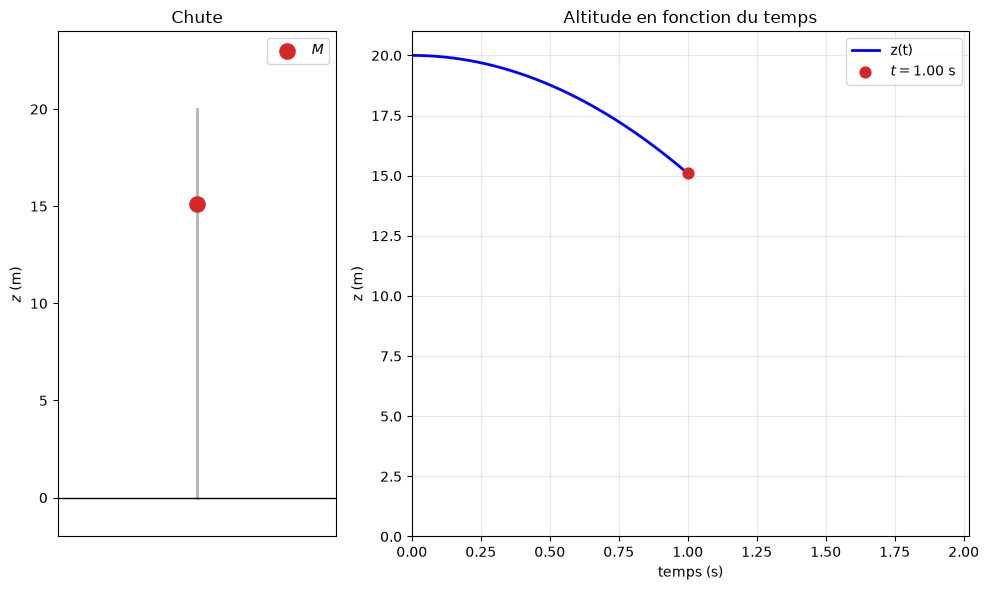

In [4]:
def tracer_chute_libre(h0=20.0, t=1.0):
    """Trace l'altitude z(t) et la position du point M lors d'une chute libre."""
    g = 9.81
    t_chute = np.sqrt(2.0 * h0 / g)
    t_affiche = min(t, t_chute)

    t_vals = np.linspace(0.0, t_affiche, 200)
    z_actuel = chute_libre(t_affiche, h0)

    fig, ax1, ax2 = tracer_trajectoire_z(t_vals, h0)

    # Colonne de chute (schéma)
    ax1.plot([0, 0], [0, h0], color='0.7', linewidth=2)
    ax1.scatter(0, z_actuel, color='tab:red', s=120, zorder=5, label='$M$')
    ax1.axhline(0, color='black', linewidth=1)
    ax1.set_xlim(-1, 1)
    ax1.set_ylim(-2, h0 * 1.1 + 2)
    ax1.set_xticks([])
    ax1.set_ylabel(r'$z$ (m)')
    ax1.set_title('Chute')
    ax1.legend(loc='upper right')

    # Courbe z(t) jusqu'à l'instant actuel, avec des limites fixes
    ax2.scatter(t_affiche, z_actuel, color='tab:red', s=60, zorder=5,
                label=rf'$t={t_affiche:.2f}$ s')
    ax2.axhline(0, color='black', linewidth=0.5)
    ax2.set_xlim(0, t_chute)
    ax2.set_ylim(0, 1.05 * h0)
    ax2.grid(alpha=0.3)
    ax2.legend(loc='upper right')

    fig.tight_layout()
    plt.show()
    plt.close(fig)

tracer_chute_libre()

In [5]:
interact(
    tracer_chute_libre,
    h0=FloatSlider(value=20.0, min=5.0, max=60.0, step=1.0, description='h0 (m)'),
    t=FloatSlider(value=1.0, min=0.0, max=5.0, step=0.05, description='t (s)'),
);

interactive(children=(FloatSlider(value=20.0, description='h0 (m)', max=60.0, min=5.0, step=1.0), FloatSlider(…

:::{admonition} 🔍 Exploration
:class: tip

1. Quelle est la forme de la courbe $z(t)$ ? Justifiez votre réponse à
   partir de l'équation horaire trouvée précédemment.
2. Faites varier $h_0$. Quelle est son influence sur la durée de la
   chute et sur la vitesse à l'arrivée au sol ?
3. Faites varier $t$. Que se passe-t-il lorsque $t$ dépasse le temps de
   chute $t_c$ ?
:::

*Écrivez vos réponses ici (Markdown, $\LaTeX$…) :*

1. --
2. --
3. --

:::{admonition} Réponses
:class: note

1. C'est une parabole, car $z(t)$ est une fonction du second degré en
   $t$ (le mouvement est uniformément accéléré).
2. Le temps de chute $t_c=\sqrt{2h_0/g}$ augmente avec $h_0$ (comme
   $\sqrt{h_0}$) ; la vitesse à l'arrivée $|v(t_c)|=\sqrt{2gh_0}$
   augmente également avec $h_0$.
3. Une fois $t>t_c$, le point $M$ a déjà atteint le sol : sa position
   reste figée à $z=0$ sur le schéma.
:::

:::{important}
Pour afficher la version interactive, ouvrez le **Notebook enseignant** en
local ou ouvrez ce notebook dans Google Colab.
:::

## 3. Chute libre : énergies

On s'intéresse maintenant à l'énergie du point matériel $M$ au cours de
sa chute, toujours sans frottement de l'air.

### 3.1 Théorie

:::{admonition} ✍️ Questions
:class: tip

1. En vous appuyant sur $v(t)$ trouvée à la section précédente,
   exprimez l'énergie cinétique $E_c$ du point $M$, par unité de
   masse, en fonction du temps.
2. En vous appuyant sur $z(t)$ trouvée à la section précédente,
   exprimez l'énergie potentielle de pesanteur $E_p$ du point $M$,
   par unité de masse, en fonction du temps.
3. Que peut-on dire de la somme de ces deux énergies (l'énergie
   mécanique $E_m$) ?
:::

*Écrivez vos réponses ici (Markdown, $\LaTeX$…) :*

1. --
2. --
3. --

:::{admonition} Réponses
:class: note

1. En utilisant $v(t)=-gt$ :

   $$
   \frac{E_c}{m} = \frac12v(t)^2 = \frac12g^2t^2
   $$
2. En utilisant $z(t)=-\frac12gt^2+h_0$ :

   $$
   \frac{E_p}{m} = g\,z(t) = -\frac12g^2t^2+gh_0
   $$
3. Leur somme, l'énergie mécanique par unité de masse, vaut
   $\dfrac{E_m}{m}=gh_0$ : elle est **constante** au cours du temps.
   C'est cohérent avec l'absence de frottement — le poids est une
   force conservative, l'énergie mécanique se conserve.
:::

:::{admonition} Appelez le professeur
:class: warning

Avant de passer à l'implémentation, faites valider votre raisonnement par
l'enseignant.
:::

### 3.2 Implémentation numérique

:::{admonition} 💻 Code
:class: tip

Complétez les fonctions `energie_cinetique` et `energie_potentielle`, qui
renvoient respectivement $E_c/m$ et $E_p/m$ à l'instant $t$. Réutilisez
la fonction `chute_libre` déjà écrite pour `energie_potentielle`.
:::

In [6]:
def energie_cinetique(t):
    """
    Calcule l'énergie cinétique par unité de masse lors d'une chute libre.

    Paramètres
    ----------
    t : float ou np.ndarray
        Instant(s) considéré(s) [s].

    Renvoie
    -------
    ec : float ou np.ndarray
        Énergie cinétique par unité de masse [J/kg].
    """
    g = 9.81
    v = -g * t
    ec = 0.5 * v**2

    return ec


def energie_potentielle(t, h0):
    """
    Calcule l'énergie potentielle de pesanteur par unité de masse lors
    d'une chute libre.

    Paramètres
    ----------
    t : float ou np.ndarray
        Instant(s) considéré(s) [s].
    h0 : float
        Hauteur initiale [m].

    Renvoie
    -------
    ep : float ou np.ndarray
        Énergie potentielle par unité de masse [J/kg].
    """
    g = 9.81
    z = chute_libre(t, h0)
    ep = g * z

    return ep

### 3.3 Analyse

Le code suivant représente l'évolution des énergies cinétique,
potentielle et mécanique **par unité de masse** au cours de la chute.
Exécutez-le, puis faites varier la hauteur initiale $h_0$.

:::{admonition} Code fourni — à exécuter
:class: note

Exécutez les cellules suivantes sans modifier le code.
:::

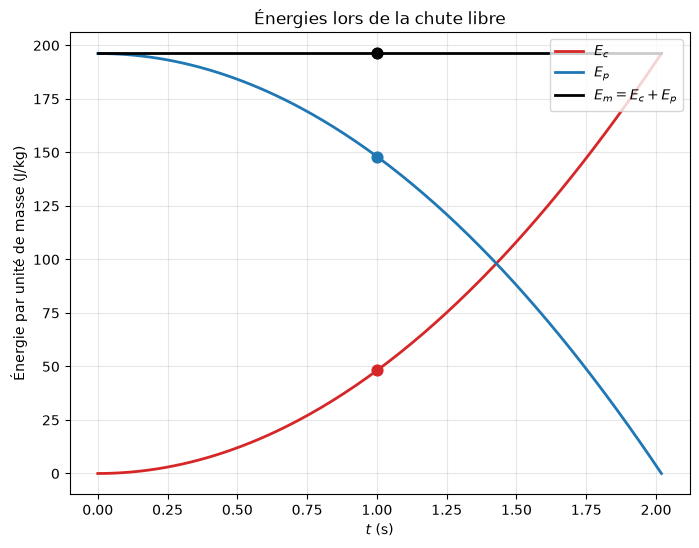

In [7]:
def tracer_energies(h0=20.0, t=1.0):
    """Trace les énergies cinétique, potentielle et mécanique lors d'une chute libre."""
    g = 9.81
    t_chute = np.sqrt(2.0 * h0 / g)
    t_affiche = min(t, t_chute)

    t_vals = np.linspace(0.0, t_chute, 200)
    ec_vals = energie_cinetique(t_vals)
    ep_vals = energie_potentielle(t_vals, h0)
    em_vals = ec_vals + ep_vals

    ec_actuel = energie_cinetique(t_affiche)
    ep_actuel = energie_potentielle(t_affiche, h0)

    fig, ax = plt.subplots(figsize=(8, 6))
    ax.plot(t_vals, ec_vals, color='tab:red', linewidth=2, label='$E_c$')
    ax.plot(t_vals, ep_vals, color='tab:blue', linewidth=2, label='$E_p$')
    ax.plot(t_vals, em_vals, color='black', linewidth=2, label='$E_m = E_c + E_p$')
    ax.scatter(t_affiche, ec_actuel, color='tab:red', s=60, zorder=5)
    ax.scatter(t_affiche, ep_actuel, color='tab:blue', s=60, zorder=5)
    ax.scatter(t_affiche, ec_actuel + ep_actuel, color='black', s=60, zorder=5)
    ax.set_xlabel(r'$t$ (s)')
    ax.set_ylabel(r'Énergie par unité de masse (J/kg)')
    ax.set_title('Énergies lors de la chute libre')
    ax.grid(alpha=0.3)
    ax.legend(loc='upper right')

    plt.show()
    plt.close(fig)

tracer_energies()

In [8]:
interact(
    tracer_energies,
    h0=FloatSlider(value=20.0, min=5.0, max=60.0, step=1.0, description='h0 (m)'),
    t=FloatSlider(value=1.0, min=0.0, max=5.0, step=0.05, description='t (s)'),
);

interactive(children=(FloatSlider(value=20.0, description='h0 (m)', max=60.0, min=5.0, step=1.0), FloatSlider(…

:::{admonition} 🔍 Exploration
:class: tip

1. Explorez le code qui permet de générer cette figure. Que fait la
   ligne `ax.scatter(...)` ?
2. Que représente la courbe noire $E_m$ au cours du temps ? Pourquoi
   cette forme est-elle cohérente avec l'absence de frottement ?
3. Comment évoluent $E_c$ et $E_p$ l'une par rapport à l'autre au
   cours de la chute ?
4. Faites varier $h_0$. Quelle est son influence sur la valeur de
   l'énergie mécanique $E_m$ ?
:::

*Écrivez vos réponses ici (Markdown, $\LaTeX$…) :*

1. --
2. --
3. --
4. --

:::{admonition} Réponses
:class: note

1. `ax.scatter(...)` place un point isolé sur la figure — ici, un
   point de couleur pour chacune des trois courbes ($E_c$, $E_p$ et
   $E_m$), à l'instant affiché.
2. La courbe noire est constante et égale à $gh_0$ : c'est l'énergie
   mécanique par unité de masse, qui se conserve car la seule force
   en jeu (le poids) est conservative — il n'y a pas de frottement
   pour dissiper de l'énergie.
3. $E_c$ croît de $0$ à $gh_0$ tandis que $E_p$ décroît de $gh_0$ à
   $0$ : l'énergie potentielle se convertit progressivement en
   énergie cinétique.
4. L'énergie mécanique $E_m=gh_0$ est directement proportionnelle à
   $h_0$.
:::

:::{important}
Pour afficher la version interactive, ouvrez le **Notebook enseignant** en
local ou ouvrez ce notebook dans Google Colab.
:::

## 4. Bilan

Ce TP a permis d'appliquer le principe fondamental de la dynamique à la
chute libre d'un point matériel, en établissant son équation horaire
$z(t)$, puis d'étudier la conservation de l'énergie mécanique en
l'absence de frottement.

À la suite de ce TP, vous devez être capable de répondre aux questions
suivantes :

1. Pourquoi l'accélération d'un point matériel en chute libre sans
   frottement est-elle constante et égale à $-g$ ?
2. Pourquoi l'énergie mécanique se conserve-t-elle en l'absence de
   frottement ?

:::{admonition} À retenir
:class: note

- Le PFD relie les forces à l'accélération :
  $\overrightarrow{F}=m\overrightarrow{a}(M)_{/R}$.
- En chute libre sans frottement, seule la gravité agit : $a_z=-g$
  (constante).
:::

:::{admonition} Compétences acquises
:class: note

À l'issue de ce TP, vous devez être capable de :

- appliquer la méthode générale de résolution d'un problème de
  dynamique (bilan des forces, PFD, projection, intégration) ;
- établir l'équation horaire d'un mouvement de chute libre sans
  frottement ;
- exprimer et interpréter l'énergie cinétique, potentielle et
  mécanique d'un point matériel ;
- construire une figure matplotlib à plusieurs axes (subplots) et
  compléter un tracé simple.
:::

**À revoir avec les profs.**